# Неделя 12 — Пользовательское NLP-приложение

Цель: Streamlit-интерфейс лучшей по validation модели. Запуск: `streamlit run app.py`. Пять новых контрольных текстов — демонстрация UI, не отдельный размеченный тестовый корпус.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'nlp_project').exists() else Path.cwd().parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import json
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown
from nlp_project.core import corpus, clean, tokens, metrics, SEED
df = corpus()
train, val, test = [df[df.split == s].copy() for s in ('train', 'validation', 'test')]


,text,sentiment,confidence,screenshot
0,The sound quality is excellent and I love thes...,Позитивный,99.6%,control_01.png
1,The battery is terrible. This phone does not w...,Негативный,100.0%,control_02.png
2,Great price and easy to use. Highly recommended.,Позитивный,100.0%,control_03.png
3,The charger broke after one day. Waste of money.,Негативный,99.8%,control_04.png
4,The design is nice but the sound is poor and I...,Позитивный,65.9%,control_05.png


{'label': 1,
 'sentiment': 'Позитивный',
 'positive_probability': 0.8457043033069147,
 'confidence': 0.8457043033069147,
 'model': 'bow_nb',
 'truncated': False}

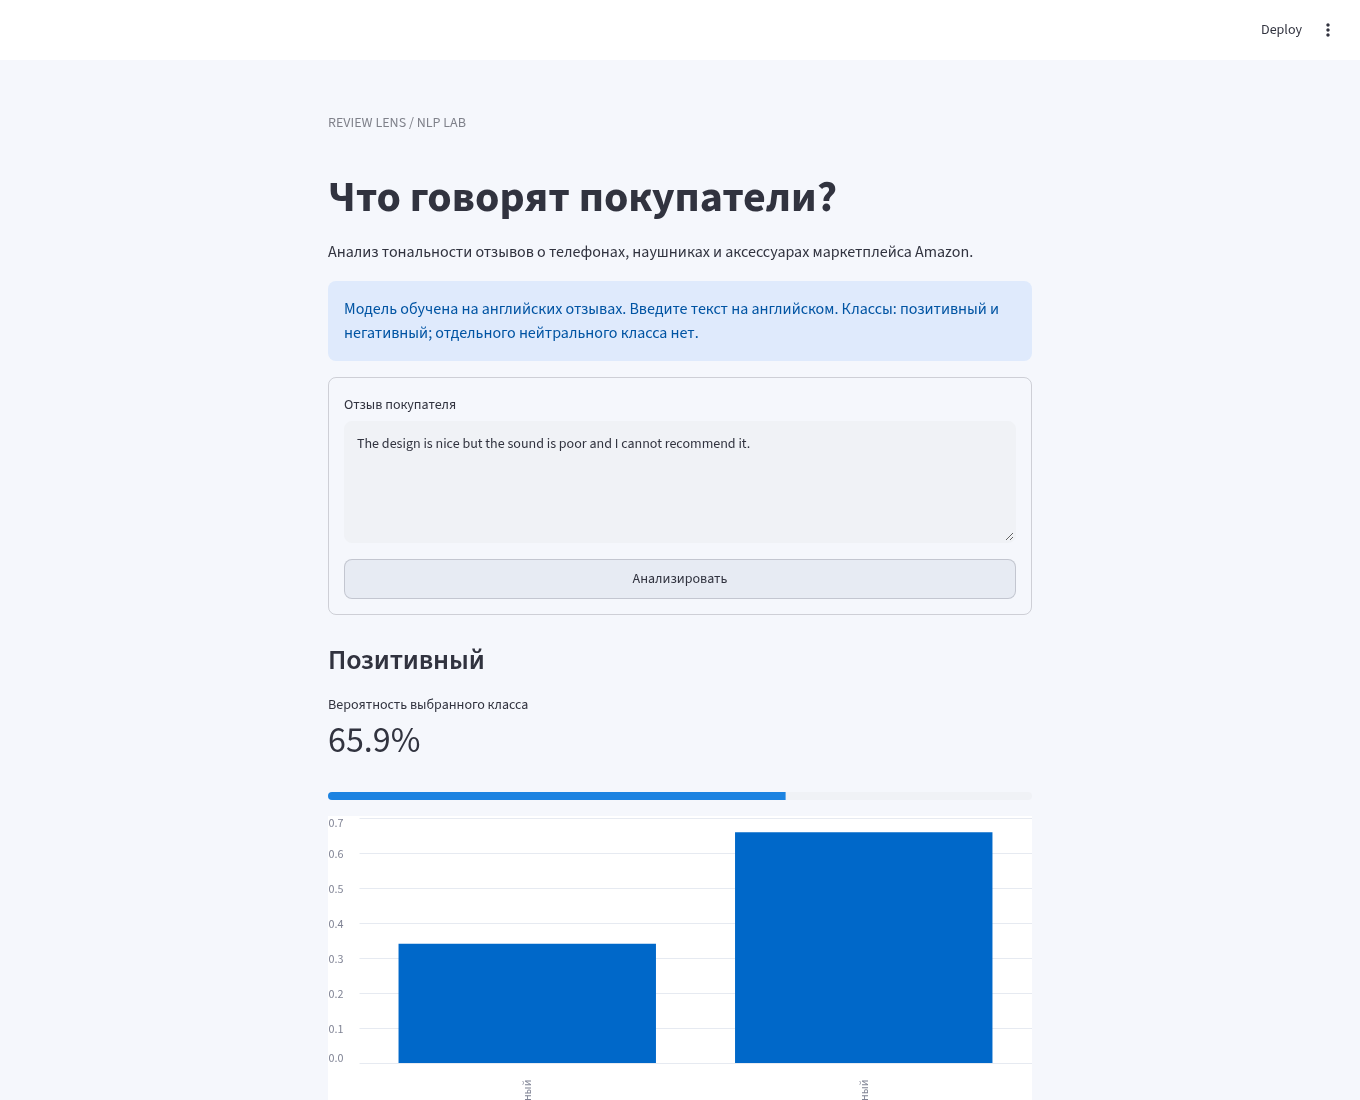

In [2]:
from nlp_project.inference import Predictor
p = Predictor()
checks = json.loads((ROOT / 'reports/ui_checks.json').read_text())
display(pd.DataFrame(checks))
display(p.predict('The sound is excellent and the battery lasts all day.'))
display(Image(filename=str(ROOT / 'reports/screenshots/control_05.png')))


## Выводы

UI возвращает класс и вероятность; уверенность не гарантирует правильность. Пятый контрольный текст смешанный и может быть классифицирован неверно. Пустой ввод, длина и язык проверяются. Скриншоты получены настоящим браузером, а не нарисованы.